# 01 — Instantaneous-turn timestep refinement

**Scientific question.** Does the unchanged instantaneous-turn model reach **practical timestep stability** when the internal timestep is reduced from 0.03125 to 0.015625 and then 0.0078125 s?

**Hypothesis A.** Aggregate social behaviour may stabilize with smaller updates. The competing possibility is that it remains sensitive because an instantaneous-turn fish can adopt a new direction at every update, so refinement increases decisions per physical second. This is not a claim of formal mathematical convergence.

We use ten matched random-start seeds (0–9), speeds 1, 3 and 5 BL/s, and the same 31.25 simulated seconds for all 90 cases. The model remains unchanged: repulsion/orientation/attraction, synchronous decide/advance, 20 fish, 20 × 20 BL reflecting arena, radii 0.5/3/5.5 BL, 360° FOV, `max_turn_rate=None`, and zero social noise. No light is added.

The final 12.5 s supplies polarization, rotation, largest-group fraction, nearest-neighbour distance and distance to centroid on the same 0.125-s observation grid. Connectivity, persistent assembly, exact overlaps and missed repulsion-zone encounters are evaluated at **every internal update**. ConnectedTimeFraction uses the entire post-initial internal trajectory. Assembly means one distance-connected component continuously for at least 5 s; a short-horizon non-success is right-censored and is not evidence that assembly is impossible.

In [1]:
from pathlib import Path
import sys

MODEL_DIR = next(
    folder for parent in (Path.cwd(), *Path.cwd().parents)
    for folder in (parent, parent / "papers")
    if (folder / "shiner_model.py").is_file() and (folder / "handlings").is_dir()
)
if str(MODEL_DIR) not in sys.path:
    sys.path.insert(0, str(MODEL_DIR))
HERE = MODEL_DIR / "handlings" / "trial_three"
PAPERS = MODEL_DIR

import json
import hashlib
import platform
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from handlings.trial_two.study_support import run_streamed
from handlings.trial_three.temporal_support import (
    METRICS, group_aggregate, compare_adjacent, protocol_candidates,
)

DATA, FIGURES = HERE / "data", HERE / "figures"
CRITERIA = json.loads((DATA / "predeclared_criteria.json").read_text())
SEEDS = CRITERIA["Seeds"]
SPEEDS = [1.0, 3.0, 5.0]
TIMESTEPS = [0.03125, 0.015625, 0.0078125]
DURATION = CRITERIA["Duration_s"]
RECORD_INTERVAL = CRITERIA["RecordingInterval_s"]
LATE_SECONDS = CRITERIA["LateWindow_s"]
MODEL_SHA = hashlib.sha256((PAPERS / "shiner_model.py").read_bytes()).hexdigest()
assert CRITERIA["DeclaredBeforeExperiments"] and MODEL_SHA == CRITERIA["ModelSHA256"]
assert len(SEEDS) == 10 and DURATION == 31.25 and RECORD_INTERVAL == 0.125
print(f"Python {platform.python_version()}; seeds {SEEDS}; 90 scientific cases")
print("Internal updates per run:", {dt: round(DURATION / dt) for dt in TIMESTEPS})
print("Records per run:", round(DURATION / RECORD_INTERVAL) + 1)
print("Shared-model SHA256:", MODEL_SHA)
# Verify path-only compatibility with the unchanged executed cache provenance.
from handlings.trial_one.relocation import executed_source_hashes


Python 3.11.16; seeds [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]; 90 scientific cases
Internal updates per run: {0.03125: 1000, 0.015625: 2000, 0.0078125: 4000}
Records per run: 251
Shared-model SHA256: 81cab7365bc33ed4b6ca06f17be6e3ca5f9b2746c5e26234aca693036259d67b


## Fixed decision criteria and controls

The criteria are loaded from `data/predeclared_criteria.json`, which was written before these results. Primary comparisons use changes in the **matched-cohort ensemble means**: absolute change ≤ 0.05 for polarization, rotation, largest-group fraction and connected-time fraction; relative change ≤ 10% for nearest-neighbour distance and distance to centroid. If the finer reference is ≤ 1e−8, the latter use an absolute 0.01-BL fallback. These are project diagnostic conventions, not biological constants or hypothesis tests.

Both adjacent timesteps must have an ensemble missed-pass rate ≤ 0.01/model/s and zero sampled exact-overlap pairs. We report whether rates decrease, including non-monotonic rare events. A candidate is selectable only if its comparison **and every finer available comparison** pass at all three speeds. The finest timestep alone cannot qualify without a finer comparator.

Paired-seed absolute differences remain visible as sensitivity diagnostics. The primary criterion does not require deterministic trajectories with different decision frequencies to remain identical. All individual case values are saved, so agreement of ensemble means does not hide paired sensitivity.

A missed pass is a straight, non-reflected relative segment entering the 0.5-BL repulsion zone with both update endpoints outside it. Wall-reflected segments are excluded by this established diagnostic, so this is not a count of every possible continuous-path encounter. MinimumRecordedPairDistance is the minimum separation at an internal update, rather than only at saved observation times. Zero exact overlaps does not imply perfect collision avoidance.

In [2]:
# The first execution runs every case freshly. Later Run All executions may reuse
# exactly matching, hash-verified results; no previous-stage results are reused.
config = {"Seeds": SEEDS, "Speeds": SPEEDS, "Timesteps": TIMESTEPS,
          "Duration_s": DURATION, "RecordingInterval_s": RECORD_INTERVAL,
          "LateWindow_s": LATE_SECONDS, "max_turn_rate": None,
          "fov_degrees": 360.0, "angular_noise": 0.0}
source_paths = [PAPERS / "shiner_model.py",
                HERE.parent / "trial_two/study_support.py",
                HERE / "temporal_support.py", DATA / "predeclared_criteria.json"]
source_hashes = executed_source_hashes(source_paths, MODEL_DIR)
cache_key = hashlib.sha256(json.dumps({"config": config, "sources": source_hashes},
                                    sort_keys=True).encode()).hexdigest()
summary_path = DATA / "01_case_summary.csv"
trace_path = DATA / "01_sampled_traces.csv"
manifest_path = DATA / "01_run_manifest.json"
manifest = json.loads(manifest_path.read_text()) if manifest_path.exists() else {}
cache_ok = manifest.get("CacheKey") == cache_key and summary_path.exists() and trace_path.exists()
if cache_ok:
    cache_ok = all(hashlib.sha256(path.read_bytes()).hexdigest() == manifest["OutputSHA256"].get(path.name)
                   for path in [summary_path, trace_path])
if cache_ok:
    summary = pd.read_csv(summary_path)
    traces = pd.read_csv(trace_path)
    print("Loaded 90 previously executed cases from the matching, hash-verified stage-3 cache.")
else:
    rows, all_traces = [], []
    started = time.perf_counter()
    for speed in SPEEDS:
        for dt in TIMESTEPS:
            for seed in SEEDS:
                row, trace, _ = run_streamed(
                    seed=seed, duration=DURATION, speed=speed, dt=dt,
                    record_interval=RECORD_INTERVAL, max_turn_rate=None,
                    fov_degrees=360.0, angular_noise=0.0,
                )
                row.update(TurningConvention="instantaneous", MaxTurnRate_rad_s=np.nan,
                           RecordingInterval_s=RECORD_INTERVAL,
                           RecordEvery=round(RECORD_INTERVAL / dt))
                trace = trace.copy()
                trace["Seed"], trace["Speed"], trace["dt"] = seed, speed, dt
                trace[["MissedPassesCumulative", "ExactOverlapsCumulative"]] = trace[
                    ["MissedPassesCumulative", "ExactOverlapsCumulative"]].fillna(0)
                rows.append(row)
                all_traces.append(trace)
            print(f"Completed speed={speed:g}, dt={dt:g}: {len(rows)}/90 cases", flush=True)
    summary = pd.DataFrame(rows)
    traces = pd.concat(all_traces, ignore_index=True)
    summary.to_csv(summary_path, index=False)
    traces.to_csv(trace_path, index=False)
    manifest = {"CacheKey": cache_key, "Config": config, "SourceSHA256": source_hashes,
                "ScientificRuns": 90, "FreshScientificRuns": 90, "ReusedPreviousStageCases": 0,
                "WallClockSeconds": time.perf_counter() - started,
                "OutputSHA256": {path.name: hashlib.sha256(path.read_bytes()).hexdigest()
                                 for path in [summary_path, trace_path]}}
    manifest_path.write_text(json.dumps(manifest, indent=2))
    print(f"Executed all 90 cases freshly in {manifest['WallClockSeconds']:.1f} s.")

assert len(summary) == 90 and not summary.duplicated(["Seed", "Speed", "dt"]).any()
assert summary.groupby(["Speed", "dt"]).size().eq(10).all()
assert summary.SavedGroupRecords.eq(round(DURATION / RECORD_INTERVAL) + 1).all()
assert summary.InternalUpdates.eq((DURATION / summary.dt).round()).all()
assert traces.groupby(["Seed", "Speed", "dt"]).size().eq(251).all()
late = traces.loc[traces.Time > DURATION - LATE_SECONDS + 1e-12]
assert late.groupby(["Seed", "Speed", "dt"]).size().eq(100).all()
assert np.isfinite(summary[METRICS].to_numpy()).all()
print("Verified: equal physical duration, complete matched seeds, 251 records per case, 100 late samples.")
display(summary[["Seed", "Speed", "dt", *METRICS, "MissedRepulsionPassesPerSecond",
                 "ExactOverlapPairs", "MinimumRecordedPairDistance", "AssemblySuccess"]].head(12))

Loaded 90 previously executed cases from the matching, hash-verified stage-3 cache.
Verified: equal physical duration, complete matched seeds, 251 records per case, 100 late samples.


,Seed,Speed,dt,Polarization,Rotation,LargestGroupFraction,ConnectedTimeFraction,MeanNND,MeanDistanceToCentroid,MissedRepulsionPassesPerSecond,ExactOverlapPairs,MinimumRecordedPairDistance,AssemblySuccess
0,0,1.0,0.031250,0.953441,0.033953,1.000,0.534,0.526461,1.169377,0.0,0,0.447175,True
1,1,1.0,0.031250,0.978700,0.023125,1.000,1.000,0.528548,1.124458,0.0,0,0.460100,True
2,2,1.0,0.031250,0.885990,0.444345,0.950,0.000,1.365818,2.166173,0.0,0,0.443575,False
3,3,1.0,0.031250,0.853005,0.610021,0.900,0.000,0.680138,2.554596,0.0,0,0.445998,False
4,4,1.0,0.031250,0.974324,0.049823,1.000,0.627,0.544044,1.241148,0.0,0,0.448210,True
5,5,1.0,0.031250,0.658249,0.122371,0.850,0.157,0.619853,3.954811,0.0,0,0.445659,False
6,6,1.0,0.031250,0.981766,0.045557,1.000,0.525,0.561061,1.132504,0.0,0,0.442898,True
7,7,1.0,0.031250,0.983817,0.021597,1.000,0.779,0.529524,1.144636,0.0,0,0.440427,True
8,8,1.0,0.031250,0.978405,0.080619,1.000,0.582,0.551184,1.150146,0.0,0,0.453934,True
9,9,1.0,0.031250,0.654682,0.221149,0.776,0.000,1.057680,4.311083,0.0,0,0.446723,False


### Independent consistency check against Stage 2

Thirty of the newly executed conditions also occurred in Stage 2 (seeds 0–4 at 0.03125 and 0.015625 s). The optional comparison below reads that archived table only **after** all 90 new runs are available. It checks that nine unchanged observer statistics reproduce those conditions exactly; previous results never replace any of this study's simulations.

In [3]:
legacy_path = HERE.parent / "trial_two/data/02_timestep_summary.csv"
if legacy_path.exists():
    previous = pd.read_csv(legacy_path)
    joined = summary.merge(previous, on=["Seed", "Speed", "dt"], suffixes=("_new", "_old"))
    checked_metrics = [*METRICS, "MissedRepulsionPassesPerSecond", "ExactOverlapPairs",
                       "MinimumRecordedPairDistance"]
    audit = []
    for metric in checked_metrics:
        differences = (joined[metric + "_new"] - joined[metric + "_old"]).abs()
        audit.append({"Metric": metric, "MatchedCases": len(joined),
                      "MaximumAbsoluteDifference": float(differences.max()),
                      "ExactlyEqual": bool(differences.eq(0).all())})
    assert len(joined) == 30 and all(row["ExactlyEqual"] for row in audit)
    (DATA / "01_previous_stage_consistency.json").write_text(json.dumps({
        "FreshCasesCompared": 30, "PreviousStageCasesReusedForScientificRuns": 0,
        "Checks": audit}, indent=2))
    display(pd.DataFrame(audit))
else:
    print("Archived Stage-2 table unavailable: optional comparison skipped; all 90 new cases remain independent.")

,Metric,MatchedCases,MaximumAbsoluteDifference,ExactlyEqual
0,Polarization,30,0.0,True
1,Rotation,30,0.0,True
2,LargestGroupFraction,30,0.0,True
3,ConnectedTimeFraction,30,0.0,True
4,MeanNND,30,0.0,True
5,MeanDistanceToCentroid,30,0.0,True
6,MissedRepulsionPassesPerSecond,30,0.0,True
7,ExactOverlapPairs,30,0.0,True
8,MinimumRecordedPairDistance,30,0.0,True


## Aggregate results and adjacent-timestep decisions

The aggregate table uses ten seeds per speed/timestep. P, R, largest-group fraction, NND and radius summarize the final 12.5 s; connected-time fraction and encounter diagnostics cover the full 31.25 s. The minimum pair distance and exact-overlap counts use every internal update. Assembly is only an informative short-horizon observation here; the final 180-s cohort is conditional on accepting a temporal protocol.

In [4]:
aggregate = group_aggregate(summary)
comparison, metric_comparison = compare_adjacent(summary, TIMESTEPS)
accepted_candidates = protocol_candidates(comparison, TIMESTEPS)
aggregate.to_csv(DATA / "01_aggregate.csv", index=False)
comparison.to_csv(DATA / "01_adjacent_comparisons.csv", index=False)
metric_comparison.to_csv(DATA / "01_metric_comparisons.csv", index=False)
assert len(aggregate) == 9 and len(comparison) == 6 and len(metric_comparison) == 36
with pd.option_context("display.max_columns", 30, "display.width", 180):
    display(aggregate.round(6))
    display(comparison.round(7))
    display(metric_comparison[["Speed", "CandidateDt", "FinerDt", "Metric", "CandidateMean",
                               "FinerMean", "AbsoluteChange", "RelativeChange",
                               "PairedMeanAbsoluteChange", "PairedRelativeChange",
                               "ToleranceKind", "Tolerance", "MetricPass"]].round(6))
print("Accepted candidate dt values across all three speeds:", accepted_candidates)

,Speed,dt,Seeds,Polarization,Rotation,LargestGroupFraction,ConnectedTimeFraction,MeanNND,MeanDistanceToCentroid,MissedRepulsionPassesPerSecond,TotalMissedRepulsionPasses,ExactOverlapPairs,MinimumRecordedPairDistance,MinimumMissedSeparation,AssemblySuccessRate,MeanAssemblyTime,PostAssemblyBreakupRuns
0,1.0,0.007812,10,0.936004,0.161401,0.93340,0.492600,0.560157,2.376880,0.0000,0,0,0.396700,NaN,0.8,12.014648,0
1,1.0,0.015625,10,0.945030,0.128253,0.98215,0.566700,0.573278,1.495437,0.0000,0,0,0.412325,NaN,0.9,11.586806,0
2,1.0,0.031250,10,0.890238,0.165256,0.94760,0.420400,0.696431,1.994893,0.0000,0,0,0.440427,NaN,0.6,10.197917,0
3,3.0,0.007812,10,0.981333,0.047891,0.99240,0.783075,0.531767,1.110568,0.0000,0,0,0.427950,NaN,0.9,4.394097,0
4,3.0,0.015625,10,0.917401,0.098837,0.95000,0.730400,0.535042,1.691452,0.0096,3,0,0.408420,0.498441,0.9,5.902778,0
5,3.0,0.031250,10,0.966295,0.055202,0.99500,0.706800,0.629439,1.166766,0.0192,6,0,0.314871,0.497110,0.9,6.791667,0
6,5.0,0.007812,10,0.988309,0.020208,1.00000,0.811650,0.526524,0.953428,0.0000,0,0,0.424470,NaN,1.0,5.892969,0
7,5.0,0.015625,10,0.962834,0.044345,0.99020,0.787850,0.548856,1.214378,0.0160,5,0,0.346705,0.497238,1.0,6.643750,0
8,5.0,0.031250,10,0.939090,0.031553,1.00000,0.842200,0.585358,1.164238,0.0928,29,0,0.195372,0.481998,1.0,4.959375,0


,Speed,CandidateDt,FinerDt,Seeds,MetricsPass,FailedMetrics,CandidateMissedPassRate,FinerMissedPassRate,CrossingRateNonIncreasing,CrossingRatePass,ExactOverlapPass,Pass
0,1.0,0.031250,0.015625,10,False,"Polarization, ConnectedTimeFraction, MeanNND, ...",0.0000,0.0000,True,True,True,False
1,1.0,0.015625,0.007812,10,False,"ConnectedTimeFraction, MeanDistanceToCentroid",0.0000,0.0000,True,True,True,False
2,3.0,0.031250,0.015625,10,False,"MeanNND, MeanDistanceToCentroid",0.0192,0.0096,True,False,True,False
3,3.0,0.015625,0.007812,10,False,"Polarization, Rotation, ConnectedTimeFraction,...",0.0096,0.0000,True,True,True,False
4,5.0,0.031250,0.015625,10,False,ConnectedTimeFraction,0.0928,0.0160,True,False,True,False
5,5.0,0.015625,0.007812,10,False,MeanDistanceToCentroid,0.0160,0.0000,True,False,True,False


,Speed,CandidateDt,FinerDt,Metric,CandidateMean,FinerMean,AbsoluteChange,RelativeChange,PairedMeanAbsoluteChange,PairedRelativeChange,ToleranceKind,Tolerance,MetricPass
0,1.0,0.031250,0.015625,Polarization,0.890238,0.945030,0.054792,0.057979,0.054792,0.057979,absolute,0.05,False
1,1.0,0.031250,0.015625,Rotation,0.165256,0.128253,0.037003,0.288514,0.067014,0.522517,absolute,0.05,True
2,1.0,0.031250,0.015625,LargestGroupFraction,0.947600,0.982150,0.034550,0.035178,0.034550,0.035178,absolute,0.05,True
3,1.0,0.031250,0.015625,ConnectedTimeFraction,0.420400,0.566700,0.146300,0.258161,0.146700,0.258867,absolute,0.05,False
4,1.0,0.031250,0.015625,MeanNND,0.696431,0.573278,0.123153,0.214823,0.133208,0.232363,relative,0.10,False
5,1.0,0.031250,0.015625,MeanDistanceToCentroid,1.994893,1.495437,0.499456,0.333987,0.706860,0.472678,relative,0.10,False
6,1.0,0.015625,0.007812,Polarization,0.945030,0.936004,0.009025,0.009642,0.037682,0.040258,absolute,0.05,True
7,1.0,0.015625,0.007812,Rotation,0.128253,0.161401,0.033148,0.205377,0.050749,0.314428,absolute,0.05,True
8,1.0,0.015625,0.007812,LargestGroupFraction,0.982150,0.933400,0.048750,0.052228,0.048750,0.052228,absolute,0.05,True
9,1.0,0.015625,0.007812,ConnectedTimeFraction,0.566700,0.492600,0.074100,0.150426,0.084200,0.170930,absolute,0.05,False


Accepted candidate dt values across all three speeds: []


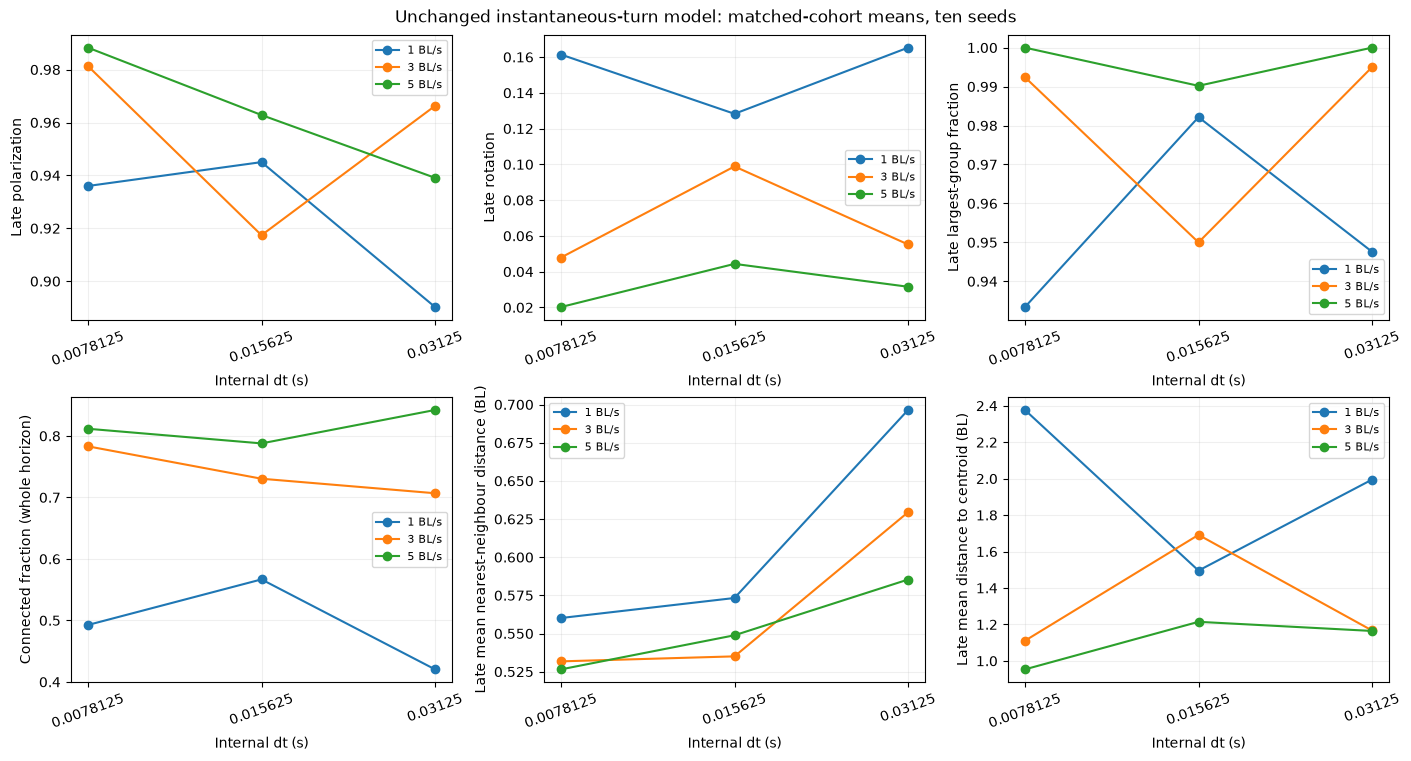

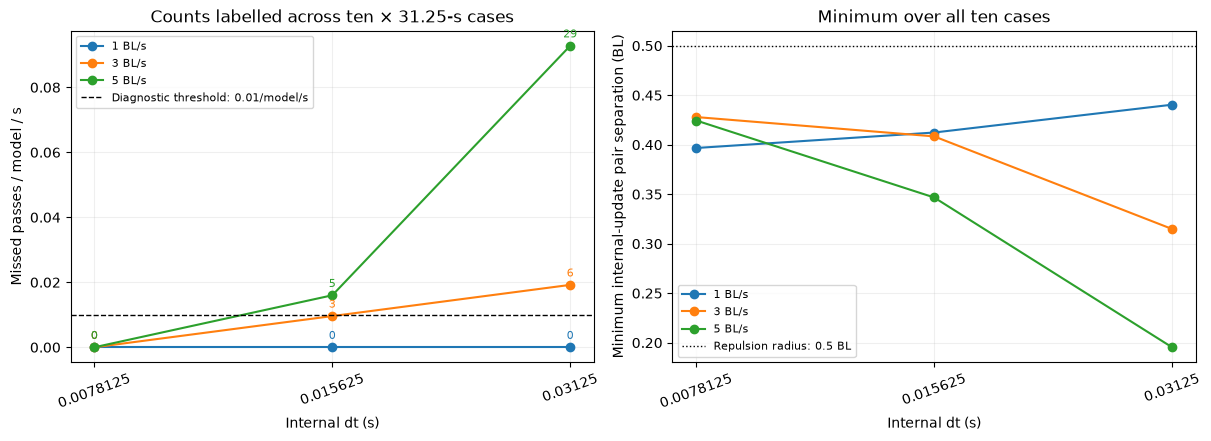

In [5]:
labels = {"Polarization": "Late polarization", "Rotation": "Late rotation",
          "LargestGroupFraction": "Late largest-group fraction",
          "ConnectedTimeFraction": "Connected fraction (whole horizon)",
          "MeanNND": "Late mean nearest-neighbour distance (BL)",
          "MeanDistanceToCentroid": "Late mean distance to centroid (BL)"}
colors = {1.0: "tab:blue", 3.0: "tab:orange", 5.0: "tab:green"}
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5), constrained_layout=True)
for ax, metric in zip(axes.flat, METRICS):
    for speed in SPEEDS:
        part = aggregate.loc[aggregate.Speed == speed].sort_values("dt")
        ax.plot(part.dt, part[metric], "o-", color=colors[speed], label=f"{speed:g} BL/s")
    ax.set(xscale="log", xlabel="Internal dt (s)", ylabel=labels[metric])
    ax.set_xticks(sorted(TIMESTEPS), [str(x) for x in sorted(TIMESTEPS)], rotation=20)
    ax.minorticks_off()
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
fig.suptitle("Unchanged instantaneous-turn model: matched-cohort means, ten seeds")
fig.savefig(FIGURES / "01a_instantaneous_aggregate_metrics.png", dpi=160)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), constrained_layout=True)
for speed in SPEEDS:
    part = aggregate.loc[aggregate.Speed == speed].sort_values("dt")
    axes[0].plot(part.dt, part.MissedRepulsionPassesPerSecond, "o-", color=colors[speed], label=f"{speed:g} BL/s")
    for row in part.itertuples():
        axes[0].annotate(str(row.TotalMissedRepulsionPasses),
                         (row.dt, row.MissedRepulsionPassesPerSecond), xytext=(0, 6),
                         textcoords="offset points", fontsize=8, ha="center", color=colors[speed])
    axes[1].plot(part.dt, part.MinimumRecordedPairDistance, "o-", color=colors[speed], label=f"{speed:g} BL/s")
axes[0].axhline(CRITERIA["MaximumMissedRepulsionPassesPerSecond"], color="black", ls="--", lw=1,
                label="Diagnostic threshold: 0.01/model/s")
axes[0].set(ylabel="Missed passes / model / s", title="Counts labelled across ten × 31.25-s cases")
axes[1].axhline(0.5, color="black", ls=":", lw=1, label="Repulsion radius: 0.5 BL")
axes[1].set(ylabel="Minimum internal-update pair separation (BL)", title="Minimum over all ten cases")
for ax in axes:
    ax.set(xscale="log", xlabel="Internal dt (s)")
    ax.set_xticks(sorted(TIMESTEPS), [str(x) for x in sorted(TIMESTEPS)], rotation=20)
    ax.minorticks_off()
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
fig.savefig(FIGURES / "01b_instantaneous_encounter_diagnostics.png", dpi=160)
plt.show()

## Matched-seed sensitivity

The following plot shows the absolute change between each seed's summaries at 0.015625 and 0.0078125 s. Dots are individual matched seeds and the line is their mean absolute change. For distance metrics, values are scaled by the finer ensemble mean to remain interpretable alongside the 10% criterion. Paired changes can exceed the change of ensemble means through cancellation; both are reported, but only ensemble changes enter the declared decision. Ten seeds and a 31.25-s window provide a finite diagnostic screen, not a guarantee for every initial condition or later physical time.

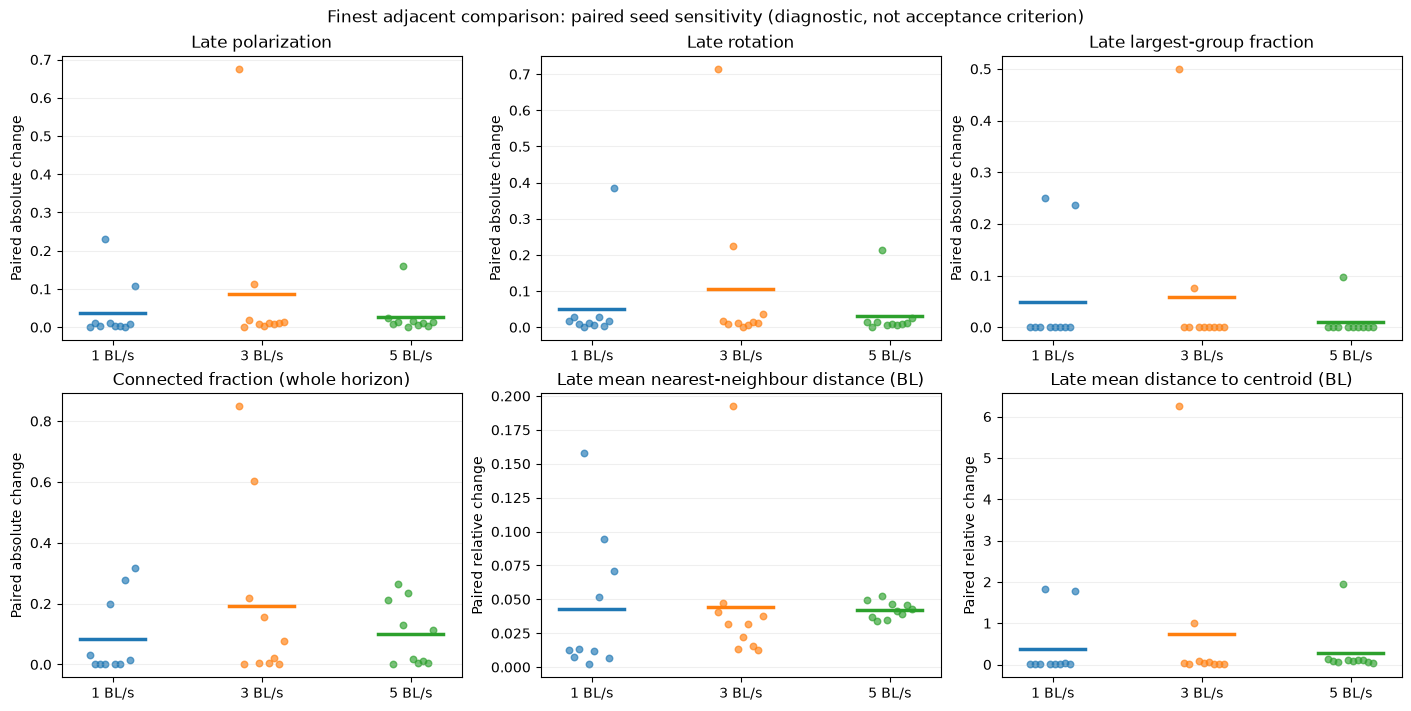

All 180 per-seed finest-pair metric changes saved in data/01_paired_seed_changes.csv.


In [6]:
paired_rows = []
coarse_dt, fine_dt = TIMESTEPS[-2:]
for speed in SPEEDS:
    coarse = summary.loc[(summary.Speed == speed) & (summary.dt == coarse_dt)].set_index("Seed")
    fine = summary.loc[(summary.Speed == speed) & (summary.dt == fine_dt)].set_index("Seed")
    for metric in METRICS:
        reference = float(fine[metric].mean())
        for seed in SEEDS:
            absolute_change = abs(float(coarse.loc[seed, metric] - fine.loc[seed, metric]))
            paired_rows.append({"Seed": seed, "Speed": speed, "Metric": metric,
                                "CandidateDt": coarse_dt, "FinerDt": fine_dt,
                                "CandidateValue": coarse.loc[seed, metric], "FinerValue": fine.loc[seed, metric],
                                "AbsoluteChange": absolute_change,
                                "RelativeChange": absolute_change / abs(reference)
                                if abs(reference) > CRITERIA["NearZeroReference"] else np.nan})
paired_cases = pd.DataFrame(paired_rows)
paired_cases.to_csv(DATA / "01_paired_seed_changes.csv", index=False)
fig, axes = plt.subplots(2, 3, figsize=(14, 7), constrained_layout=True)
for ax, metric in zip(axes.flat, METRICS):
    relative = CRITERIA["MetricRules"][metric]["kind"] == "relative"
    column = "RelativeChange" if relative else "AbsoluteChange"
    for x, speed in enumerate(SPEEDS):
        part = paired_cases.loc[(paired_cases.Speed == speed) & (paired_cases.Metric == metric)]
        jitter = np.linspace(-0.15, 0.15, len(part))
        ax.scatter(np.full(len(part), x) + jitter, part[column], s=22, alpha=0.65, color=colors[speed])
        ax.plot([x - 0.22, x + 0.22], [part[column].mean()] * 2, color=colors[speed], lw=2.5)
    ax.set(xticks=range(3), xticklabels=[f"{s:g} BL/s" for s in SPEEDS],
           ylabel="Paired relative change" if relative else "Paired absolute change", title=labels[metric])
    ax.grid(axis="y", alpha=0.2)
fig.suptitle("Finest adjacent comparison: paired seed sensitivity (diagnostic, not acceptance criterion)")
fig.savefig(FIGURES / "01c_instantaneous_paired_sensitivity.png", dpi=160)
plt.show()
print("All 180 per-seed finest-pair metric changes saved in data/01_paired_seed_changes.csv.")

In [7]:
finest_pair = comparison.loc[comparison.CandidateDt == TIMESTEPS[-2]]
findings = {
    "ScientificRuns": 90, "FreshScientificRuns": 90, "ReusedPreviousStageCases": 0,
    "Seeds": SEEDS, "Speeds": SPEEDS, "Timesteps": TIMESTEPS,
    "PhysicalDuration_s": DURATION, "LateWindow_s": LATE_SECONDS,
    "RecordingInterval_s": RECORD_INTERVAL, "TurningConvention": "instantaneous",
    "MaxTurnRate_rad_s": None, "FOV_degrees": 360.0, "AngularNoise": 0.0,
    "PredeclaredCriteria": "predeclared_criteria.json", "ModelSHA256": MODEL_SHA,
    "AcceptedCandidateTimesteps_s": accepted_candidates,
    "AnyCandidateAcceptedAcrossAllSpeeds": bool(accepted_candidates),
    "FinestAdjacentComparisonPassesAllSpeeds": bool(finest_pair.Pass.all()),
    "ExactOverlapPairsAcrossAllRuns": int(summary.ExactOverlapPairs.sum()),
    "TotalMissedRepulsionPasses": int(summary.MissedRepulsionPasses.sum()),
    "MinimumRecordedPairDistance_BL": float(summary.MinimumRecordedPairDistance.min()),
    "PerSpeedAdjacentDecisions": comparison.to_dict(orient="records"),
    "Verdict": "PRACTICAL TIMESTEP STABILITY CANDIDATE" if accepted_candidates else "NO ACCEPTED INSTANTANEOUS-TURN PROTOCOL",
    "Limitation": "Finite ten-seed, 31.25-s aggregate diagnostic screen; instantaneous refinement changes social decision frequency. Final light readiness requires the independent protocol decision, final long-horizon cohort and regenerated validated checkpoints.",
}
(DATA / "01_findings.json").write_text(json.dumps(findings, indent=2))
lines = ["## Executed interpretation", "",
         f"All **90 cases** completed with **{findings['ExactOverlapPairsAcrossAllRuns']} sampled exact-overlap pairs**. "
         f"The minimum internal-update pair separation over every case was **{findings['MinimumRecordedPairDistance_BL']:.6f} BL**.", ""]
for row in comparison.itertuples():
    failures = row.FailedMetrics if row.FailedMetrics else "none"
    lines.append(f"- **{row.Speed:g} BL/s, {row.CandidateDt:g} → {row.FinerDt:g} s:** "
                 f"{'PASS' if row.Pass else 'FAIL'}; failed metric screens: {failures}; "
                 f"missed-pass rate {row.CandidateMissedPassRate:.5f} → {row.FinerMissedPassRate:.5f}/model/s.")
lines += ["", f"**Across-speed candidate timesteps:** {accepted_candidates if accepted_candidates else 'none'}.", "",
          "This notebook evaluates practical timestep stability of the original formulation. "
          "It does not choose a light protocol on its own. The bounded-turn comparison and the conditional final validation remain separate decisions."]
display(Markdown("\n".join(lines)))

## Executed interpretation

All **90 cases** completed with **0 sampled exact-overlap pairs**. The minimum internal-update pair separation over every case was **0.195372 BL**.

- **1 BL/s, 0.03125 → 0.015625 s:** FAIL; failed metric screens: Polarization, ConnectedTimeFraction, MeanNND, MeanDistanceToCentroid; missed-pass rate 0.00000 → 0.00000/model/s.
- **1 BL/s, 0.015625 → 0.0078125 s:** FAIL; failed metric screens: ConnectedTimeFraction, MeanDistanceToCentroid; missed-pass rate 0.00000 → 0.00000/model/s.
- **3 BL/s, 0.03125 → 0.015625 s:** FAIL; failed metric screens: MeanNND, MeanDistanceToCentroid; missed-pass rate 0.01920 → 0.00960/model/s.
- **3 BL/s, 0.015625 → 0.0078125 s:** FAIL; failed metric screens: Polarization, Rotation, ConnectedTimeFraction, MeanDistanceToCentroid; missed-pass rate 0.00960 → 0.00000/model/s.
- **5 BL/s, 0.03125 → 0.015625 s:** FAIL; failed metric screens: ConnectedTimeFraction; missed-pass rate 0.09280 → 0.01600/model/s.
- **5 BL/s, 0.015625 → 0.0078125 s:** FAIL; failed metric screens: MeanDistanceToCentroid; missed-pass rate 0.01600 → 0.00000/model/s.

**Across-speed candidate timesteps:** none.

This notebook evaluates practical timestep stability of the original formulation. It does not choose a light protocol on its own. The bounded-turn comparison and the conditional final validation remain separate decisions.

## Why these checks are informative

Matching seeds holds the initial positions and headings fixed while changing only the internal timestep. Equal simulated duration prevents finer runs from covering less physical time. A common recording grid prevents a change in sample count from driving the late metric comparison. Internal-update observers catch events that a sparse plotted trajectory would miss.

Polarization and rotation describe collective motion; connected fraction and largest-group fraction expose separation that motion metrics alone can hide; NND and radius reveal spatial compression or dispersion; missed repulsion passes expose under-resolved close encounters. Persistent assembly is included to make short-horizon censoring visible, while the longer final cohort must establish assembly under any newly selected protocol.

The three timesteps can support or reject only practical stability over these seeds, speeds and observation window. Bounded turning is tested independently in notebook 03; this notebook never assumes that formulation will perform better.

## Result of this execution

**No instantaneous-turn candidate passes across all three speeds.** In the finest adjacent comparison (0.015625 → 0.0078125 s), the ensemble radius changes by **37.08%, 52.31% and 27.37%** at 1, 3 and 5 BL/s, respectively; all exceed the predeclared 10% convention. At speed 1, connected-time fraction also changes by 0.07410. At speed 3, polarization changes by 0.06393, rotation by 0.05095 and connected-time fraction by 0.05268, exceeding their 0.05 limits.

Refinement resolves the observed straight-path missed encounters more effectively: at speed 5, rates fall from **0.0928 → 0.0160 → 0/model/s**. The finer rate alone does not rescue the 0.015625-s candidate because that candidate still exceeds the 0.01/s screen and radius remains sensitive. There are zero sampled exact overlaps in all 90 cases; the minimum update-sampled separation rises from 0.19537 BL at the coarsest speed-5 condition to 0.42447 BL at its finest condition.

A few matched seeds strongly influence the spatial averages. For example, at speed 3, seed 0 has late mean radius 7.98733 BL at 0.015625 s and 1.04572 BL at 0.0078125 s. The paired plot preserves these differences. This is evidence of unresolved practical sensitivity over the declared finite cohort and horizon, rather than proof that no limiting behaviour can exist. Notebook 03 tests the alternative turning formulation independently.
